# Tutorial 2: Combining the Five Traffic-Count Files
### MIS Data Analytics Case Competition — City of Norman

The City gave us **five traffic-count files** from ACOG (the regional planning agency): FY19, FY21, FY23, FY25 and
FY26. They are *almost* the same, but not quite. In this tutorial you will:

1. Load the five files and **compare their columns**
2. **Rename** the columns so all files speak the same language, then **stack** them into one table
3. Turn text like `NB 2,009vpd / SB 1,889vpd` into a **number**
4. Apply the City's rule: use the **highest** volume
5. Cut roads into one-mile **sections** (segments)
6. Add the **number of lanes** with a **merge**
7. Compute **capacity** and the **volume-to-capacity (V/C) ratio**

We only use `pandas`, `seaborn` and simple Python (functions, loops, dictionaries).

---
## Step 0 — Setup

Put the five ACOG files and `lanes_lookup.csv` in your group's Google Drive folder, then connect Drive.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DATA_FOLDER = '/content/drive/MyDrive/Colab Notebooks/MIS3213/Norman_Traffic_Analysis/data/'      # <-- change to your folder

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)

---
## Step 1 — Load the five files

We store the five tables in a **dictionary**, so `raw['FY23']` gives the FY23 table.

In [ ]:
YEARS = ['FY19', 'FY21', 'FY23', 'FY25', 'FY26']

raw = {}
for year in YEARS:
    raw[year] = pd.read_excel(DATA_FOLDER + 'ACOG ' + year + '.xlsx')
    print(year, raw[year].shape)

FY19 (100, 14)
FY21 (100, 17)
FY23 (100, 12)
FY25 (101, 12)
FY26 (101, 12)


Same kind of data, but **different shapes**: 12, 14 or 17 columns. Let's see what is different.

In [ ]:
raw['FY19'].head(3)

,Loc ID,County,Community,Functional Class,On,From,To,Approach,Dir,Latitude,Longitude,Latest,Latest Date,Unnamed: 13
0,52500-110,Cleveland,Norman,Collector,Imhoff Rd W,Chautauqua,Jenkins,NaN,2-WAY,35.189588,-97.447258,7270,2017-01-01,"EB 2,913vpd - 37mph / WB 2,651vpd - 37mph (12-..."
1,52500-118,Cleveland,Norman,Minor Arterial,W Indian Hills Rd,48th Ave.NW,36th Ave.NW,NaN,2-WAY,35.290583,-97.499254,4962,2017-01-01,"EB 2,827vpd -65mph / WB 2,686vpd - 63mph (3-15..."
2,52500-146,Cleveland,Norman,-,W Main St,48 th W,Willoway Dr,NaN,2-WAY,35.218399,-97.505958,5355,2016-01-01,"EB 2,671vpd - 39mph / WB 2,361vpd - 45mph (3-1..."


In [ ]:
raw['FY26'].head(3)

,LOCAL_ID,COUNTY,COMMUNITY,ON_ROAD,FROM,TO,DIR,LATITUDE,LONGITUDE,LATEST_COUNT,LATEST_DATE,NEW COUNT
0,52500-267,Cleveland,Norman,120th Ave.NE,Hilltop Dr,Alameda Dr.,2-WAY,35.235200,-97.265203,NB 727vpd - 60mph / SB 781vpd 64mph 12/5/25,NaN,NaN
1,52500-268,Cleveland,Norman,120th Ave.NE,Indian Hills Rd.,Franklin Rd.,2-WAY,35.282674,-97.265203,"NB 1,001vpd - <75mph / SB 1,051vpd - 70mph 12/...",NaN,NaN
2,52500-255,Cleveland,Norman,12th Ave NE,Franklin,Kinston Rd,2-WAY,35.257062,-97.423657,"NB 7,970vpd - 63mph / SB 8,046vpd - 54mph 2/20/26",NaN,NaN


## Step 2 — Compare the columns

We build a small table: one row per column name, one column per year, with ✓ where the file has that column.

In [ ]:
all_columns = []
for year in YEARS:
    for c in raw[year].columns:
        if c not in all_columns:
            all_columns.append(c)

comparison = pd.DataFrame(index=all_columns)
for year in YEARS:
    comparison[year] = ['✓' if c in raw[year].columns else '' for c in all_columns]
comparison

,FY19,FY21,FY23,FY25,FY26
Loc ID,✓,✓,✓,✓,
County,✓,✓,✓,✓,
Community,✓,✓,✓,✓,
Functional Class,✓,✓,✓,✓,
On,✓,✓,✓,✓,
From,✓,✓,✓,✓,
To,✓,✓,✓,✓,
Approach,✓,✓,✓,✓,
Dir,✓,✓,,,
Latitude,✓,✓,✓,✓,


What we learn:

| Problem | Example |
|---|---|
| **Different names for the same thing** | `On` (FY19–FY25) vs `ON_ROAD` (FY26); `Latitude` vs `LATITUDE` |
| **Columns only some years have** | `Latest` (a number) only in FY19 and FY21; `Functional Class` missing in FY26 |
| **Unnamed columns** | `Unnamed: 13`, `Unnamed: 11` — the count is written as **text** there |
| **Empty columns** | `Column1`, `NEW COUNT` |

Let's check which columns are completely empty:

In [ ]:
for year in YEARS:
    empty = [c for c in raw[year].columns if raw[year][c].isna().all()]
    print(year, 'empty columns:', empty)

FY19 empty columns: []
FY21 empty columns: ['Column1']
FY23 empty columns: ['Column1']
FY25 empty columns: ['Column1']
FY26 empty columns: ['LATEST_DATE', 'NEW COUNT']


### What goes wrong if we just stack them?
`pd.concat` lines up columns **by name**. Columns with different names become **separate** columns, full of `NaN`:

In [ ]:
naive = pd.concat(raw.values(), ignore_index=True)
print('Shape:', naive.shape)
print('Missing values per column:')
naive.isna().sum()

Shape: (502, 31)
Missing values per column:


,0
Loc ID,102
County,102
Community,102
Functional Class,102
On,101
From,106
To,107
Approach,432
Dir,302
Latitude,102


31 columns and lots of `NaN` — the road name is split between `On` and `ON_ROAD`, the latitude between `Latitude`
and `LATITUDE`, and so on. We need to **rename first**.

---
## Step 3 — Rename to standard names, then stack

We choose one **standard name** for each piece of information and write a rename dictionary for each year.
The City told us where the volume is in each file:
* FY19: `Latest` (a number) **and** a second count as text in the last column (`Unnamed: 13`)
* FY21: `Latest` **and** text in `Unnamed: 16`
* FY23 and FY25: only text, in `Unnamed: 11`
* FY26: only text, in `LATEST_COUNT`

In [ ]:
RENAME = {
    'FY19': {'Loc ID': 'station', 'Functional Class': 'func_class', 'On': 'road_name', 'From': 'from_road',
             'To': 'to_road', 'Latitude': 'lat', 'Longitude': 'lon', 'Latest': 'latest', 'Unnamed: 13': 'count_text'},
    'FY21': {'Loc ID': 'station', 'Functional Class': 'func_class', 'On': 'road_name', 'From': 'from_road',
             'To': 'to_road', 'Latitude': 'lat', 'Longitude': 'lon', 'Latest': 'latest', 'Unnamed: 16': 'count_text'},
    'FY23': {'Loc ID': 'station', 'Functional Class': 'func_class', 'On': 'road_name', 'From': 'from_road',
             'To': 'to_road', 'Latitude': 'lat', 'Longitude': 'lon', 'Unnamed: 11': 'count_text'},
    'FY25': {'Loc ID': 'station', 'Functional Class': 'func_class', 'On': 'road_name', 'From': 'from_road',
             'To': 'to_road', 'Latitude': 'lat', 'Longitude': 'lon', 'Unnamed: 11': 'count_text'},
    'FY26': {'LOCAL_ID': 'station', 'ON_ROAD': 'road_name', 'FROM': 'from_road', 'TO': 'to_road',
             'LATITUDE': 'lat', 'LONGITUDE': 'lon', 'LATEST_COUNT': 'count_text'},
}

pieces = []
for year in YEARS:
    table = raw[year].rename(columns=RENAME[year])               # 1. rename
    keep = list(RENAME[year].values())
    table = table[keep].copy()                                   # 2. keep only the renamed columns
    table['year'] = year                                         # 3. remember which file it came from
    pieces.append(table)

traffic = pd.concat(pieces, ignore_index=True)                   # 4. stack
print('Shape:', traffic.shape)
traffic.head()

Shape: (502, 10)


,station,func_class,road_name,from_road,to_road,lat,lon,latest,count_text,year
0,52500-110,Collector,Imhoff Rd W,Chautauqua,Jenkins,35.189588,-97.447258,7270.0,"EB 2,913vpd - 37mph / WB 2,651vpd - 37mph (12-...",FY19
1,52500-118,Minor Arterial,W Indian Hills Rd,48th Ave.NW,36th Ave.NW,35.290583,-97.499254,4962.0,"EB 2,827vpd -65mph / WB 2,686vpd - 63mph (3-15...",FY19
2,52500-146,-,W Main St,48 th W,Willoway Dr,35.218399,-97.505958,5355.0,"EB 2,671vpd - 39mph / WB 2,361vpd - 45mph (3-1...",FY19
3,52500-151,-,E Main St,Carter,12 th E,35.225586,-97.427659,7007.0,"EB 3,786vpd - 45mph / WB 3,121 - 50mph (9-21-18)",FY19
4,52500-155,Minor Arterial,E Main St,James Garner Ave,Peters Ave,35.221381,-97.442245,10033.0,"ONE WAY street, EB 6,765vpd - 30mph (12-7-18)",FY19


Now we have **11 columns**. A column that a file did not have (e.g. `latest` in FY23) is simply `NaN` for that
file's rows. `groupby('year').count()` shows how many **non-missing** values each year has:

In [ ]:
traffic.groupby('year').count()

,station,func_class,road_name,from_road,to_road,lat,lon,latest,count_text
year,,,,,,,,,
FY19,100,100,100,97,97,100,100,100,100
FY21,100,100,100,98,97,100,100,100,100
FY23,100,100,100,100,100,100,100,0,100
FY25,100,100,101,101,101,100,100,0,100
FY26,100,0,101,101,101,100,100,0,101


**Reuse tip:** when the City sends FY27, you only add one line to `RENAME` and `'FY27'` to `YEARS`.

---
## Step 4 — Clean up rows

Some rows have **no road name** (blank lines) and two rows at the bottom of FY25/FY26 have **no coordinates**.
Without a location we cannot place them on a road, so we set them aside.

In [ ]:
print('Rows without a road name:', traffic['road_name'].isna().sum())
traffic = traffic[traffic['road_name'].notna()]

no_location = traffic[traffic['lat'].isna() | traffic['lon'].isna()]
print('Rows without coordinates:')
print(no_location[['year', 'station', 'road_name', 'from_road', 'to_road', 'count_text']])

traffic = traffic[traffic['lat'].notna() & traffic['lon'].notna()].copy()
print('Rows left:', len(traffic))

Rows without a road name: 0
Rows without coordinates:
     year station    road_name    from_road      to_road  \
400  FY25     NaN   Lindsey St  60th Ave SE  72nd Ave SE   
501  FY26     NaN  Jenkins Ave    Apache St     Duffy St   

                                            count_text  
400      EB 274vpd - 53mph / WB 230vpd - 63mph 4/18/25  
501  NB 1,892vpd - 33mph / SB 2,002vpd - 32mph 4/10/26  
Rows left: 500


---
## Step 5 — Turn the count text into a number

The text looks like `NB 2,009vpd - 55mph / SB 1,889vpd - 61mph (3/31/23)`. The daily volume is
**2,009 + 1,889 = 3,898** vehicles per day (vpd). The `mph` numbers are speeds and the end is the date.

Our function reads the text **word by word** and adds up the words that are volumes.

In [ ]:
traffic.head()

,station,func_class,road_name,from_road,to_road,lat,lon,latest,count_text,year
0,52500-110,Collector,Imhoff Rd W,Chautauqua,Jenkins,35.189588,-97.447258,7270.0,"EB 2,913vpd - 37mph / WB 2,651vpd - 37mph (12-...",FY19
1,52500-118,Minor Arterial,W Indian Hills Rd,48th Ave.NW,36th Ave.NW,35.290583,-97.499254,4962.0,"EB 2,827vpd -65mph / WB 2,686vpd - 63mph (3-15...",FY19
2,52500-146,-,W Main St,48 th W,Willoway Dr,35.218399,-97.505958,5355.0,"EB 2,671vpd - 39mph / WB 2,361vpd - 45mph (3-1...",FY19
3,52500-151,-,E Main St,Carter,12 th E,35.225586,-97.427659,7007.0,"EB 3,786vpd - 45mph / WB 3,121 - 50mph (9-21-18)",FY19
4,52500-155,Minor Arterial,E Main St,James Garner Ave,Peters Ave,35.221381,-97.442245,10033.0,"ONE WAY street, EB 6,765vpd - 30mph (12-7-18)",FY19


In [ ]:
TEXT_FIXES = {'3,3339vpd': '3,339vpd',    # a typo in FY19 (one digit too many)
              ', ': ','}                   # "13, 892vpd" -> "13,892vpd"

def read_volume(text):
    if not isinstance(text, str):
        return None
    for wrong, right in TEXT_FIXES.items():
        text = text.replace(wrong, right)
    for label in ['NB', 'SB', 'EB', 'WB']:
        text = text.replace(label, ' ')                  # "WB4,871vpd" -> " 4,871vpd"
    words = text.split()
    total = 0
    found = False
    for i in range(len(words)):
        word = words[i]
        if 'mph' in word or '/' in word or '-' in word or '(' in word or ')' in word:
            continue                                     # a speed or a date
        if i + 1 < len(words) and words[i + 1].startswith('mph'):
            continue                                     # "49 mph"
        number = word.replace('vpd', '').replace('vph', '').replace(',', '')
        if number.isdigit():
            total = total + int(number)
            found = True
    return total if found else None

print(read_volume('NB 2,009vpd - 55mph / SB 1,889vpd - 61mph (3/31/23)'))
print(read_volume('NB 3,643vpd -55mph / SB 3,241vpd / 49 mph 4/3/26'))
print(read_volume('Under widening construction.  Please see below rpl...'))

3898
6884
None


In [ ]:
traffic['text_volume'] = traffic['count_text'].apply(read_volume)
traffic[['year', 'road_name', 'latest', 'count_text', 'text_volume']].head(8)

,year,road_name,latest,count_text,text_volume
0,FY19,Imhoff Rd W,7270.0,"EB 2,913vpd - 37mph / WB 2,651vpd - 37mph (12-...",5564.0
1,FY19,W Indian Hills Rd,4962.0,"EB 2,827vpd -65mph / WB 2,686vpd - 63mph (3-15...",5513.0
2,FY19,W Main St,5355.0,"EB 2,671vpd - 39mph / WB 2,361vpd - 45mph (3-1...",5032.0
3,FY19,E Main St,7007.0,"EB 3,786vpd - 45mph / WB 3,121 - 50mph (9-21-18)",6907.0
4,FY19,E Main St,10033.0,"ONE WAY street, EB 6,765vpd - 30mph (12-7-18)",6765.0
5,FY19,W Robinson St,20696.0,"EB 10,912vpd - 42mph / WB 10,337vpd - 49mph (3...",21249.0
6,FY19,Se 60th Ave Se,1246.0,NB 842vpd - 56mph / SB 951vpd - 50 mph (10-26-18),1793.0
7,FY19,W Robinson St,9555.0,"EB 5,383vpd - 48mph / WB 5,170vpd - 48mph (3-8...",10553.0


In [ ]:
traffic.head()

,station,func_class,road_name,from_road,to_road,lat,lon,latest,count_text,year,text_volume
0,52500-110,Collector,Imhoff Rd W,Chautauqua,Jenkins,35.189588,-97.447258,7270.0,"EB 2,913vpd - 37mph / WB 2,651vpd - 37mph (12-...",FY19,5564.0
1,52500-118,Minor Arterial,W Indian Hills Rd,48th Ave.NW,36th Ave.NW,35.290583,-97.499254,4962.0,"EB 2,827vpd -65mph / WB 2,686vpd - 63mph (3-15...",FY19,5513.0
2,52500-146,-,W Main St,48 th W,Willoway Dr,35.218399,-97.505958,5355.0,"EB 2,671vpd - 39mph / WB 2,361vpd - 45mph (3-1...",FY19,5032.0
3,52500-151,-,E Main St,Carter,12 th E,35.225586,-97.427659,7007.0,"EB 3,786vpd - 45mph / WB 3,121 - 50mph (9-21-18)",FY19,6907.0
4,52500-155,Minor Arterial,E Main St,James Garner Ave,Peters Ave,35.221381,-97.442245,10033.0,"ONE WAY street, EB 6,765vpd - 30mph (12-7-18)",FY19,6765.0


### FY19 and FY21 have **two** counts
`latest` is one count and `count_text` is a **different, newer** count. The City's rule: use the **highest**.
`max(axis=1)` takes the largest value **across columns** in each row (ignoring `NaN`).

In [ ]:
traffic['volume'] = traffic[['latest', 'text_volume']].max(axis=1)

two_counts = traffic[traffic['latest'].notna()]
print('Rows with two counts:', len(two_counts))
print('...where the text count is higher:', (two_counts['text_volume'] > two_counts['latest']).sum())
print('Rows with no volume at all:', traffic['volume'].isna().sum())

Rows with two counts: 200
...where the text count is higher: 70
Rows with no volume at all: 2


In [ ]:
traffic.head()

,station,func_class,road_name,from_road,to_road,lat,lon,latest,count_text,year,text_volume,volume
0,52500-110,Collector,Imhoff Rd W,Chautauqua,Jenkins,35.189588,-97.447258,7270.0,"EB 2,913vpd - 37mph / WB 2,651vpd - 37mph (12-...",FY19,5564.0,7270.0
1,52500-118,Minor Arterial,W Indian Hills Rd,48th Ave.NW,36th Ave.NW,35.290583,-97.499254,4962.0,"EB 2,827vpd -65mph / WB 2,686vpd - 63mph (3-15...",FY19,5513.0,5513.0
2,52500-146,-,W Main St,48 th W,Willoway Dr,35.218399,-97.505958,5355.0,"EB 2,671vpd - 39mph / WB 2,361vpd - 45mph (3-1...",FY19,5032.0,5355.0
3,52500-151,-,E Main St,Carter,12 th E,35.225586,-97.427659,7007.0,"EB 3,786vpd - 45mph / WB 3,121 - 50mph (9-21-18)",FY19,6907.0,7007.0
4,52500-155,Minor Arterial,E Main St,James Garner Ave,Peters Ave,35.221381,-97.442245,10033.0,"ONE WAY street, EB 6,765vpd - 30mph (12-7-18)",FY19,6765.0,10033.0


### Look at the volumes
A **histogram** shows how volumes are spread; a **box plot by year** compares the years.

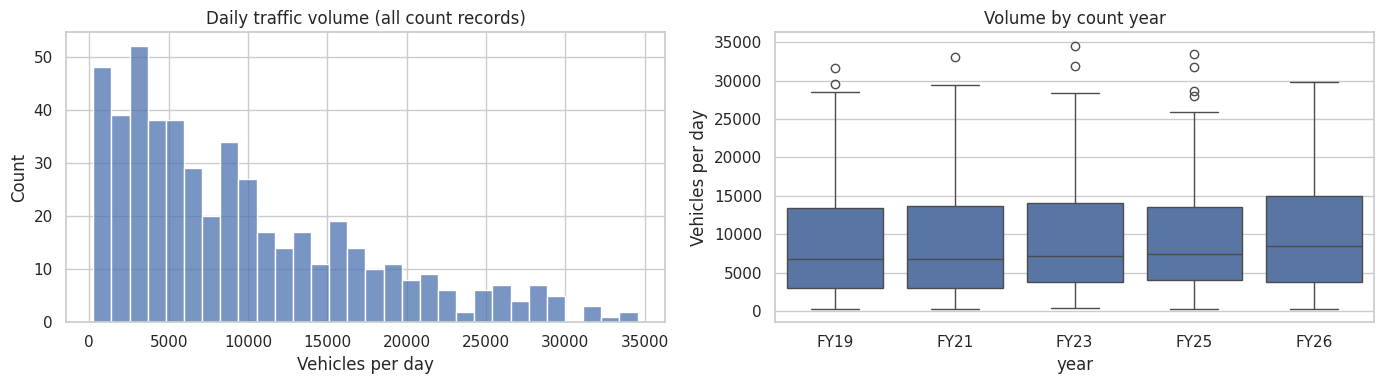

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=traffic, x='volume', bins=30, ax=axes[0])
axes[0].set_title('Daily traffic volume (all count records)')
axes[0].set_xlabel('Vehicles per day')
sns.boxplot(data=traffic, x='year', y='volume', ax=axes[1])
axes[1].set_title('Volume by count year')
axes[1].set_ylabel('Vehicles per day')
plt.tight_layout()
plt.show()

---
## Step 6 — Clean the road names

The same road is written many different ways:

In [ ]:
traffic[traffic['road_name'].str.contains('Robinson', case=False)]['road_name'].value_counts()

,count
road_name,
W Robinson St,15
E Robinson St E,7
E Robinson St,4


We write a function that makes one **road key** per road: upper case, no punctuation, no direction letters
(N, S, E, W) and no street types (AVE, ST, RD...). Numbered avenues keep their **side of town**: *12th Ave NE* and
*12th Ave SE* are one road (`12TH E`), but *12th Ave NW* is another road a mile west (`12TH W`).

In [ ]:
REMOVE_WORDS = ['N', 'S', 'E', 'W', 'AVE', 'AVENUE', 'ST', 'STREET', 'RD', 'ROAD', 'BLVD', 'BLV', 'DR', 'PKWY',
                'LN', 'LANE', 'HWY', 'CT', 'CIR', 'PL', 'TRL', 'WAY']
QUADRANTS = ['NE', 'NW', 'SE', 'SW']
NAME_ALIASES = {'CEDAR': 'CEDAR LANE', 'STATE 9': 'SH 9'}

def road_key(name):
    name = name.upper()
    for ch in '.,()':
        name = name.replace(ch, ' ')
    side = ''
    kept = []
    for word in name.split():
        if word in QUADRANTS:
            side = word[1]                 # 'NE' -> 'E'
        elif word not in REMOVE_WORDS:
            kept.append(word)
    key = ' '.join(kept)
    key = NAME_ALIASES.get(key, key)
    if key[:1].isdigit():                  # numbered avenue: add the side
        key = key + ' ' + side
    return key

traffic['road'] = traffic['road_name'].apply(road_key)
traffic[['road_name', 'road']].drop_duplicates().head(12)

,road_name,road
0,Imhoff Rd W,IMHOFF
1,W Indian Hills Rd,INDIAN HILLS
2,W Main St,MAIN
3,E Main St,MAIN
5,W Robinson St,ROBINSON
6,Se 60th Ave Se,60TH E
10,W Rock Creek Rd,ROCK CREEK
11,W Tecumseh Rd,TECUMSEH
14,60th Ave NW,60TH W
16,S University Blvd,UNIVERSITY


Three station names in FY23 are garbled, e.g. `(E Lindsey St)12th Ave NW`. Each station has an **ID** that never
changes, so we can see the real road in the other years and fix them by ID:

In [ ]:
print(traffic[traffic['station'] == '52500-135'][['year', 'road_name']])

NAME_FIXES_BY_ID = {'52500-135': 'LINDSEY', '52500-16': '48TH W', '52500-293': 'INDIAN HILLS'}
for station_id, right_name in NAME_FIXES_BY_ID.items():
    traffic.loc[(traffic['station'] == station_id) & (traffic['year'] == 'FY23'), 'road'] = right_name

     year                  road_name
201  FY23  (E Lindsey St)12th Ave NW
301  FY25               E Lindsey St
455  FY26               E Lindsey St


---
## Step 7 — The same station across years (pivot table)

A **pivot table** turns the long table (one row per station per year) into a wide table (one row per station, one
column per year). It makes the City's "highest volume" rule easy to see.

In [ ]:
by_station = traffic.pivot_table(index=['station', 'road'], columns='year', values='volume', aggfunc='max')
by_station['highest'] = by_station.max(axis=1)
by_station.sort_values('highest', ascending=False).head(10)

,year,FY19,FY21,FY23,FY25,FY26,highest
station,road,,,,,,
52500-157,MAIN,NaN,NaN,34556.0,33443.0,NaN,34556.0
52500-192,ROBINSON,NaN,33112.0,NaN,NaN,NaN,33112.0
52500-158,MAIN,NaN,NaN,31886.0,31815.0,NaN,31886.0
52500-260,12TH E,31629.0,28410.0,NaN,NaN,29131.0,31629.0
52500-63,CLASSEN,NaN,NaN,NaN,NaN,29872.0,29872.0
52500-187,ROBINSON,29585.0,NaN,28317.0,28006.0,NaN,29585.0
52500-185,ROBINSON,NaN,29463.0,NaN,NaN,NaN,29463.0
52500-194,ROBINSON,NaN,29431.0,NaN,NaN,NaN,29431.0
52500-153,MAIN,NaN,NaN,27750.0,28681.0,NaN,28681.0


A **line chart** of the five busiest stations across the years. A station with one dot was counted only once; when
a station was skipped in some years, the line jumps straight over those years.

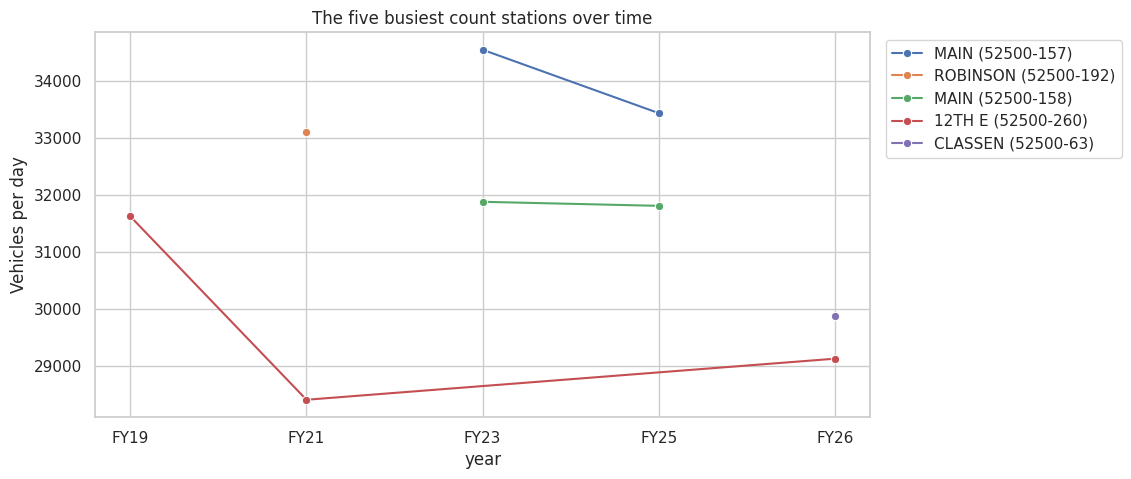

In [ ]:
top5 = by_station.sort_values('highest', ascending=False).head(5)
top5_long = top5[YEARS].reset_index().melt(id_vars=['station', 'road'], var_name='year', value_name='volume')
top5_long['label'] = top5_long['road'] + ' (' + top5_long['station'] + ')'

plt.figure(figsize=(10, 5))
sns.lineplot(data=top5_long, x='year', y='volume', hue='label', marker='o')
plt.title('The five busiest count stations over time')
plt.ylabel('Vehicles per day')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.show()

---
## Step 8 — Sections of road (segments)

The City wants segments **at least one mile long**, e.g. *Rock Creek Rd between 12th Ave NE and 24th Ave NE*. Norman's
main roads sit on a **one-mile grid**, so:

> **segment = one road between two neighboring grid roads**

```
           24th Ave NW     12th Ave NW      Porter Ave
  Robinson ──────┼═════════════════┼────────────────┼──    ← "Robinson: 24th Ave NW – 12th Ave NW"
                 │                 │                │
  Main ──────────┼─────────────────┼────────────────┼──
```

For an **east–west** road we use the station's **longitude** to find the grid roads to its west and east.
For a **north–south** road we use its **latitude** to find the grid roads to its south and north.

In [ ]:
NS_GRID = {   # north-south grid roads: longitude -> name
    -97.5473: '72nd Ave NW/SW', -97.5296: '60th Ave NW/SW', -97.5120: '48th Ave NW/SW',
    -97.4943: '36th Ave NW/SW', -97.4767: '24th Ave NW/SW', -97.4590: '12th Ave NW / Berry Rd',
    -97.4412: 'Porter Ave / Jenkins Ave', -97.4236: '12th Ave NE/SE', -97.4059: '24th Ave NE/SE',
    -97.3882: '36th Ave NE/SE', -97.3706: '48th Ave NE/SE', -97.3530: '60th Ave NE/SE',
    -97.3354: '72nd Ave NE/SE', -97.3180: '84th Ave NE/SE', -97.3004: '96th Ave NE/SE',
    -97.2828: '108th Ave NE/SE', -97.2652: '120th Ave NE/SE', -97.2476: '132nd Ave NE/SE',
    -97.2300: '144th Ave NE/SE', -97.2123: '156th Ave NE/SE', -97.1945: '168th Ave NE/SE', -97.1770: '180th Ave NE/SE'}
EW_GRID = {   # east-west grid roads: latitude -> name
    35.3340: 'County line', 35.3195: 'Stella Rd', 35.3051: 'Bethel Rd', 35.2908: 'Indian Hills Rd',
    35.2763: 'Franklin Rd', 35.2619: 'Tecumseh Rd', 35.2474: 'Rock Creek Rd', 35.2329: 'Robinson St',
    35.2184: 'Main St / Alameda St', 35.2039: 'Lindsey St', 35.1894: 'Imhoff Rd', 35.1751: 'Cedar Lane Rd',
    35.1604: 'Post Oak Rd', 35.1458: 'Etowah Rd', 35.1313: 'Slaughterville Rd'}

NORTH_SOUTH_ROADS = ['BERRY', 'PORTER', 'JENKINS', 'FLOOD', 'CLASSEN', 'CHAUTAUQUA', 'UNIVERSITY',
                     'WEBSTER', 'JAMES GARNER', 'ED NOBLE', 'BROADWAY']

def is_north_south(road):
    return road in NORTH_SOUTH_ROADS or road[:1].isdigit()

def find_between(value, grid):
    positions = sorted(grid.keys())
    for i in range(len(positions) - 1):
        if positions[i] <= value < positions[i + 1]:
            return grid[positions[i]], grid[positions[i + 1]]
    return None, None

def road_title(road):
    if road[:1].isdigit():
        number, side = road.split()
        return number.lower() + ' Ave ' + ('NE/SE' if side == 'E' else 'NW/SW')
    return road.title()

def make_segment(row):
    if is_north_south(row['road']):
        start, end = find_between(row['lat'], EW_GRID)
    else:
        start, end = find_between(row['lon'], NS_GRID)
    if start is None:
        return None
    return road_title(row['road']) + ': ' + start + ' – ' + end

traffic['segment'] = traffic.apply(make_segment, axis=1)
traffic[['year', 'road_name', 'from_road', 'to_road', 'segment']].head(10)

,year,road_name,from_road,to_road,segment
0,FY19,Imhoff Rd W,Chautauqua,Jenkins,Imhoff: 12th Ave NW / Berry Rd – Porter Ave / ...
1,FY19,W Indian Hills Rd,48th Ave.NW,36th Ave.NW,Indian Hills: 48th Ave NW/SW – 36th Ave NW/SW
2,FY19,W Main St,48 th W,Willoway Dr,Main: 48th Ave NW/SW – 36th Ave NW/SW
3,FY19,E Main St,Carter,12 th E,Main: Porter Ave / Jenkins Ave – 12th Ave NE/SE
4,FY19,E Main St,James Garner Ave,Peters Ave,Main: 12th Ave NW / Berry Rd – Porter Ave / Je...
5,FY19,W Robinson St,36th Ave.NW,I-35,Robinson: 36th Ave NW/SW – 24th Ave NW/SW
6,FY19,Se 60th Ave Se,Alameda,Lindsey,60th Ave NE/SE: Lindsey St – Main St / Alameda St
7,FY19,W Robinson St,Estates Dr,36 th W,Robinson: 48th Ave NW/SW – 36th Ave NW/SW
8,FY19,W Robinson St,60th Ave.NW,Cabella Ct.,Robinson: 60th Ave NW/SW – 48th Ave NW/SW
9,FY19,W Robinson St,I-35,24th Ave.NW,Robinson: 36th Ave NW/SW – 24th Ave NW/SW


Compare `from_road`/`to_road` (ACOG's short count section) with our `segment` (the whole mile): the segment always
contains the count section.

### Which roads belong in the study?
The City's *Jargon* sheet: use **Principal Arterials, Minor Arterials and Section-Line Roads**; do **not** use
freeways (I-35, SH-9), collectors or local streets. Section-line roads (the grid roads) are always in; other roads are
in if ACOG calls any of their stations an arterial.

Roads left out: ['BOYD', 'BROADWAY', 'BROOKS', 'CHAUTAUQUA', 'CONSTITUTION', 'DAWS', 'ED NOBLE', 'EUFAULA', 'JAMES GARNER', 'SH 9', 'SYMMES', 'UNIVERSITY', 'WEBSTER']


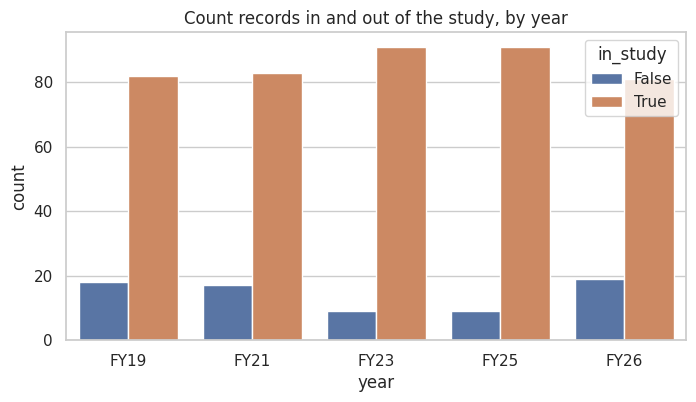

In [ ]:
SECTION_LINE_ROADS = ['ROBINSON', 'MAIN', 'ALAMEDA', 'LINDSEY',
                      'IMHOFF', 'CEDAR LANE', 'POST OAK', 'ETOWAH',
                      'TECUMSEH', 'ROCK CREEK', 'FRANKLIN', 'INDIAN HILLS', 'BETHEL', 'STELLA',
                      'BERRY', 'PORTER', 'JENKINS']
FREEWAYS = ['SH 9', 'I 35', 'INTERSTATE']
MANUAL_EXCLUDE = ['DAWS']        # ACOG says Minor Arterial, but it is a ~800 vpd campus street

arterial_roads = traffic[traffic['func_class'].isin(['Principal Arterial', 'Minor Arterial'])]['road'].unique()

def in_study(road):
    if road in FREEWAYS or road in MANUAL_EXCLUDE:
        return False
    return road in SECTION_LINE_ROADS or road[:1].isdigit() or road in arterial_roads

traffic['in_study'] = traffic['road'].apply(in_study)
print('Roads left out:', sorted(traffic[~traffic['in_study']]['road'].unique()))

plt.figure(figsize=(8, 4))
sns.countplot(data=traffic, x='year', hue='in_study')
plt.title('Count records in and out of the study, by year')
plt.show()

### One row per segment — the highest volume wins
A segment may have **several stations** and **several years**. `groupby` + `max` applies the City's rule.

In [ ]:
study = traffic[traffic['in_study'] & traffic['volume'].notna() & traffic['segment'].notna()]

segments = study.groupby('segment').agg(road=('road', 'first'),
                                        volume=('volume', 'max'),
                                        stations=('station', 'nunique'),
                                        records=('volume', 'count')).reset_index()
print('Segments:', len(segments))
segments.sort_values('volume', ascending=False).head(10)

Segments: 127


,segment,road,volume,stations,records
94,Main: 36th Ave NW/SW – 24th Ave NW/SW,MAIN,34556.0,4,8
105,Robinson: 12th Ave NW / Berry Rd – Porter Ave ...,ROBINSON,33112.0,3,3
4,12th Ave NE/SE: Main St / Alameda St – Robinso...,12TH E,31629.0,2,6
58,Classen: Imhoff Rd – Lindsey St,CLASSEN,29872.0,4,4
108,Robinson: 36th Ave NW/SW – 24th Ave NW/SW,ROBINSON,29585.0,2,6
107,Robinson: 24th Ave NW/SW – 12th Ave NW / Berry Rd,ROBINSON,27525.0,2,2
3,12th Ave NE/SE: Lindsey St – Main St / Alameda St,12TH E,27247.0,1,4
64,Flood: Rock Creek Rd – Tecumseh Rd,FLOOD,26174.0,1,3
93,Main: 24th Ave NW/SW – 12th Ave NW / Berry Rd,MAIN,25937.0,2,4
91,Lindsey: 36th Ave NW/SW – 24th Ave NW/SW,LINDSEY,25354.0,1,2


Example: one segment, all its records. The segment volume is the **largest** of these.

In [ ]:
example = 'Robinson: 12th Ave NW / Berry Rd – Porter Ave / Jenkins Ave'
study[study['segment'] == example][['year', 'station', 'road_name', 'from_road', 'to_road', 'volume']]

,year,station,road_name,from_road,to_road,volume
102,FY21,52500-185,W Robinson St,Berry,Newton Dr,29463.0
104,FY21,52500-192,W Robinson St,N. Flood Ave.,Stubbeman Ave,33112.0
105,FY21,52500-194,E Robinson St E,Peters Ave,Porter,29431.0


---
## Step 9 — Number of lanes

**Capacity** (how many vehicles a road can carry per day) depends on the **number of lanes in both directions**:

| Code | What you see on the aerial photo |
|---|---|
| `2` | one lane each way |
| `3` | one lane each way + a center turn lane |
| `4U` | two lanes each way, **undivided** (just a painted line) |
| `4D` | two lanes each way, **divided** (a median / island) |
| `5` | two lanes each way + a center turn lane |
| `6U` / `6D` | three lanes each way, undivided / divided |
| `1W2` | one-way street with 2 lanes |

Lanes come from the City's aerial map (normanok.gov › City Maps › Interactive Map). They are stored in
`lanes_lookup.csv`, one row per segment. The values provided are **estimates — check them!**

In [ ]:
lanes = pd.read_csv(DATA_FOLDER + 'lanes_lookup.csv', dtype=str)
lanes.head()

,segment,lanes,source,notes
0,120th Ave NE/SE: Robinson St – Rock Creek Rd,2,estimate – verify on aerial,rural/2-lane section
1,120th Ave NE/SE: Franklin Rd – Indian Hills Rd,2,estimate – verify on aerial,rural/2-lane section
2,12th Ave NE/SE: Lindsey St – Main St / Alameda St,4D,estimate – verify on aerial,NaN
3,12th Ave NE/SE: Main St / Alameda St – Robinso...,4D,estimate – verify on aerial,NaN
4,12th Ave NE/SE: Robinson St – Rock Creek Rd,4U,estimate – verify on aerial,NaN


### Merge lanes into the segments
`pd.merge` joins two tables on a shared column — here `segment`. We use a **left** merge (keep every segment) and
`indicator=True`, which adds a `_merge` column telling us whether each segment found a match.

_merge
both          127
left_only       0
right_only      0
Name: count, dtype: int64
Segments without lanes: []


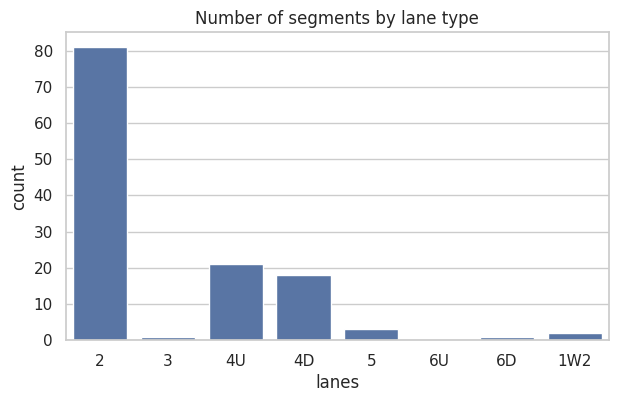

In [ ]:
segments = pd.merge(segments, lanes[['segment', 'lanes']], on='segment', how='left', indicator=True)
print(segments['_merge'].value_counts())
print('Segments without lanes:', list(segments[segments['_merge'] == 'left_only']['segment']))

segments['lanes'] = segments['lanes'].fillna('2')       # assume 2 lanes if unknown (and go check!)
segments = segments.drop(columns='_merge')

plt.figure(figsize=(7, 4))
sns.countplot(data=segments, x='lanes', order=['2', '3', '4U', '4D', '5', '6U', '6D', '1W2'])
plt.title('Number of segments by lane type')
plt.show()

---
## Step 10 — Capacity and the V/C ratio

ACOG's table gives the daily capacity for each road type. There are two columns: **LOS C** (2020 plan) and
**LOS E** (2025 plan, the newer one). We put both in dictionaries and use **`map`** to look them up.

In [ ]:
CAPACITY_LOS_E = {'2': 17100, '3': 17100, '4U': 34200, '4D': 38000, '5': 36000,
                  '6U': 52300, '6D': 58000, '1W2': 22000, '1W3': 33000}
CAPACITY_LOS_C = {'2': 10000, '3': 10000, '4U': 22000, '4D': 26000, '5': 24000,
                  '6U': 32000, '6D': 40000, '1W2': 12000, '1W3': 18000}

segments['capacity'] = segments['lanes'].map(CAPACITY_LOS_E)
segments['vc'] = (segments['volume'] / segments['capacity']).round(3)
segments[['segment', 'volume', 'lanes', 'capacity', 'vc']].sort_values('vc', ascending=False).head(10)

,segment,volume,lanes,capacity,vc
6,12th Ave NE/SE: Rock Creek Rd – Tecumseh Rd,16637.0,2,17100,0.973
105,Robinson: 12th Ave NW / Berry Rd – Porter Ave ...,33112.0,5,36000,0.920
4,12th Ave NE/SE: Main St / Alameda St – Robinso...,31629.0,4D,38000,0.832
58,Classen: Imhoff Rd – Lindsey St,29872.0,4D,38000,0.786
108,Robinson: 36th Ave NW/SW – 24th Ave NW/SW,29585.0,4D,38000,0.779
107,Robinson: 24th Ave NW/SW – 12th Ave NW / Berry Rd,27525.0,5,36000,0.765
2,12th Ave NE/SE: Franklin Rd – Indian Hills Rd,13037.0,2,17100,0.762
93,Main: 24th Ave NW/SW – 12th Ave NW / Berry Rd,25937.0,5,36000,0.720
3,12th Ave NE/SE: Lindsey St – Main St / Alameda St,27247.0,4D,38000,0.717
84,Jenkins: Imhoff Rd – Lindsey St,12124.0,2,17100,0.709


**V/C** = volume ÷ capacity.
* **0.5** → the road carries half of what it can handle
* **1.0** → it carries exactly its capacity
* **above 1.0** → **over capacity** (congested)

`pd.cut` puts the numbers into **groups**:

In [ ]:
segments['vc_level'] = pd.cut(segments['vc'], bins=[0, 0.5, 0.75, 1.0, 10],
                              labels=['Low (< 0.50)', 'Moderate (0.50–0.75)', 'Near capacity (0.75–1.0)', 'Over capacity (> 1.0)'])
segments['vc_level'].value_counts().sort_index()

,count
vc_level,
Low (< 0.50),88
Moderate (0.50–0.75),32
Near capacity (0.75–1.0),7
Over capacity (> 1.0),0


### Charts
**Top 15 by V/C**, colored by level:

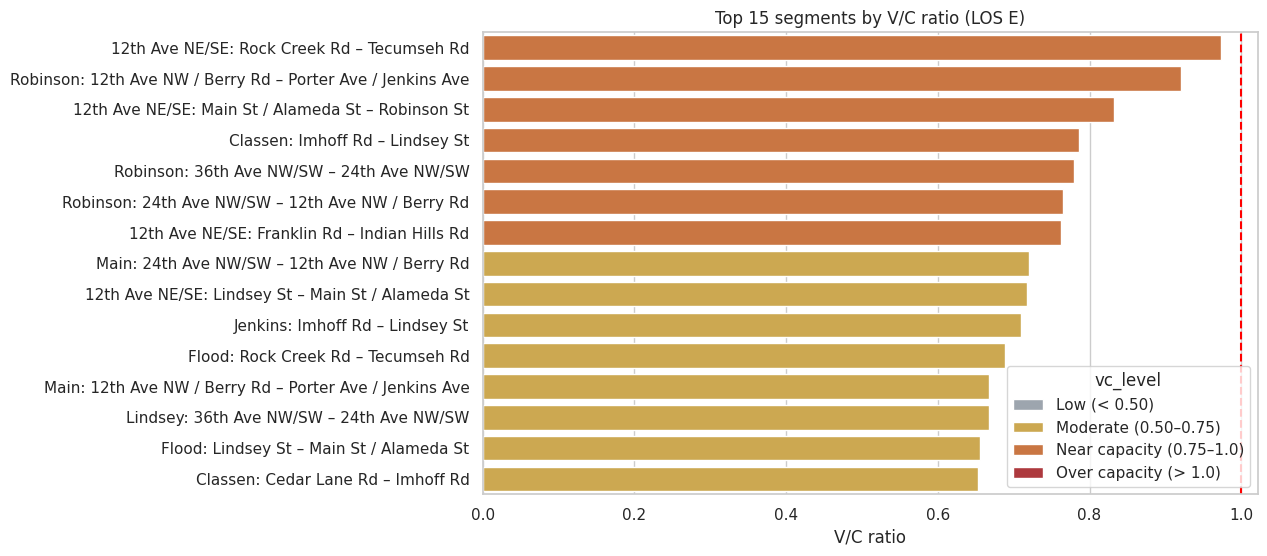

In [ ]:
LEVEL_COLORS = {'Low (< 0.50)': '#9aa5b1', 'Moderate (0.50–0.75)': '#e0b03c',
                'Near capacity (0.75–1.0)': '#e0702c', 'Over capacity (> 1.0)': '#c0262d'}

top15 = segments.sort_values('vc', ascending=False).head(15)
plt.figure(figsize=(10, 6))
sns.barplot(data=top15, x='vc', y='segment', hue='vc_level', palette=LEVEL_COLORS, dodge=False)
plt.axvline(1.0, color='red', linestyle='--')
plt.title('Top 15 segments by V/C ratio (LOS E)')
plt.xlabel('V/C ratio')
plt.ylabel('')
plt.show()

**Volume vs capacity.** Every segment is a dot. Dots **above the red line** have volume > capacity (V/C > 1).

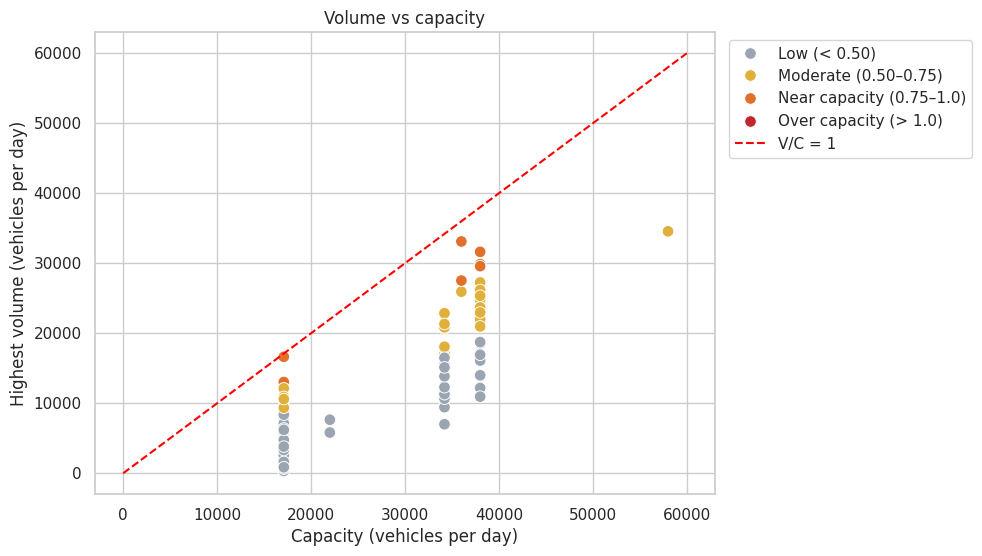

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=segments, x='capacity', y='volume', hue='vc_level', palette=LEVEL_COLORS, s=70)
plt.plot([0, 60000], [0, 60000], color='red', linestyle='--', label='V/C = 1')
plt.title('Volume vs capacity')
plt.xlabel('Capacity (vehicles per day)')
plt.ylabel('Highest volume (vehicles per day)')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.show()

### Why lanes matter so much
What if we had assumed **every road is 2 lanes**? Or used **LOS C** instead of LOS E?

In [ ]:
vc_if_2_lanes = segments['volume'] / CAPACITY_LOS_E['2']
vc_los_c = segments['volume'] / segments['lanes'].map(CAPACITY_LOS_C)

print('Over capacity with our lanes (LOS E):', (segments['vc'] > 1).sum())
print('Over capacity if every road had 2 lanes:', (vc_if_2_lanes > 1).sum())
print('Over capacity with LOS C capacities:', (vc_los_c > 1).sum())

Over capacity with our lanes (LOS E): 0
Over capacity if every road had 2 lanes: 25
Over capacity with LOS C capacities: 17


The **ranking** barely changes between LOS C and LOS E (the numbers move together), but the **lane counts** change
the ranking a lot. That is why checking lanes on the aerial map is important.

---
## Step 11 — Save your work

In [ ]:
segments.to_csv(DATA_FOLDER + 'segments_vc.csv', index=False)
print('Saved', len(segments), 'segments to segments_vc.csv')

Saved 127 segments to segments_vc.csv


---
## Summary

| Step | pandas / seaborn tool |
|---|---|
| Compare columns of several files | loops, `isna().all()` |
| Make columns match, then stack | `rename(columns=...)`, `pd.concat` |
| Text → number | a function + `apply` |
| Highest of two columns | `max(axis=1)` |
| Same station across years | `pivot_table`, `melt`, `sns.lineplot` |
| One row per segment, highest volume | `groupby(...).agg(...)` |
| Add lanes from another file | `pd.merge(..., how='left', indicator=True)` |
| Look up capacity | `map(dictionary)` |
| Group numbers into levels | `pd.cut` |
| Charts | `histplot`, `boxplot`, `countplot`, `barplot`, `scatterplot` |

